In [1]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn


%matplotlib inline
import slmsuite
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib as mpl
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase
from matplotlib import pyplot as plt
from src.plots import *
from src.config import base_path
from src.utils import get_cam
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
from slmsuite.holography.algorithms import FeedbackHologram

from src.slm_initialise import slm_initialise
from src.utils import plot_cam
import pickle
%load_ext autoreload
%autoreload 2
# mpl.rc('image', cmap='Blues')

In [2]:
#Create a virtual SLM and camera
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
wav_um = 1.064
slm_shape = (1024, 1280) # (give height, width)
cam_shape = (1080,1440) # (give height, width)
slm = SimulatedSLM((slm_shape[1], slm_shape[0]), pitch_um=(8, 8), wav_um=wav_um) #(width,height)
slm.set_source_analytic(sim=True,x0 =  100*8, y0 = 0, a =  1, c = 0,wx = 500*8,wy = 500*8)
slm.fit_source_amplitude()
cam = SimulatedCamera(slm,(cam_shape[1], cam_shape[0]), pitch_um=(3.45,3.45)) #(width,height)
# The setup (a FourierSLM setup with a camera placed in the Fourier plane of an SLM) holds the camera and SLM.
# Tie the camera and SLM together with an analytic calibration.
fs = FourierSLM(cam, slm)
M, b = fs.fourier_calibration_build(
    f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
    theta=5 * np.pi / 180,
)
cam.set_affine(M, b)
fs.fourier_calibrate_analytic(M, b)


{'M': array([[24578.57759466, -2150.34690512],
        [ 2150.34690512, 24578.57759466]]),
 'b': array([[720.],
        [540.]]),
 'a': array([[0],
        [0]]),
 '__version__': '0.2.1',
 '__time__': '2025-08-13 15:06:36.950823',
 '__timestamp__': 1755115596.950823,
 '__meta__': {'__class__': '<slmsuite.hardware.cameraslms.FourierSLM object at 0x0000020BB81657F0>',
  'name': 'camera-SLM',
  'cam': {'__class__': '<slmsuite.hardware.cameras.simulated.SimulatedCamera object at 0x0000020BE09DB470>',
   'name': 'camera',
   'shape': (1080, 1440),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([3.45, 3.45]),
   'exposure_s': 1,
   'exposure_bounds_s': None,
   'averaging': None,
   'hdr': None,
   'woi': (0, 1440, 0, 1080),
   'default_shape': (1080, 1440)},
  'slm': {'__class__': '<slmsuite.hardware.slms.simulated.SimulatedSLM object at 0x0000020BDE410500>',
   'name': 'SLM',
   'shape': (1024, 1280),
   'bitdepth': 8,
   'bitresolution': 256,
   'pitch_um': array([8., 8.]

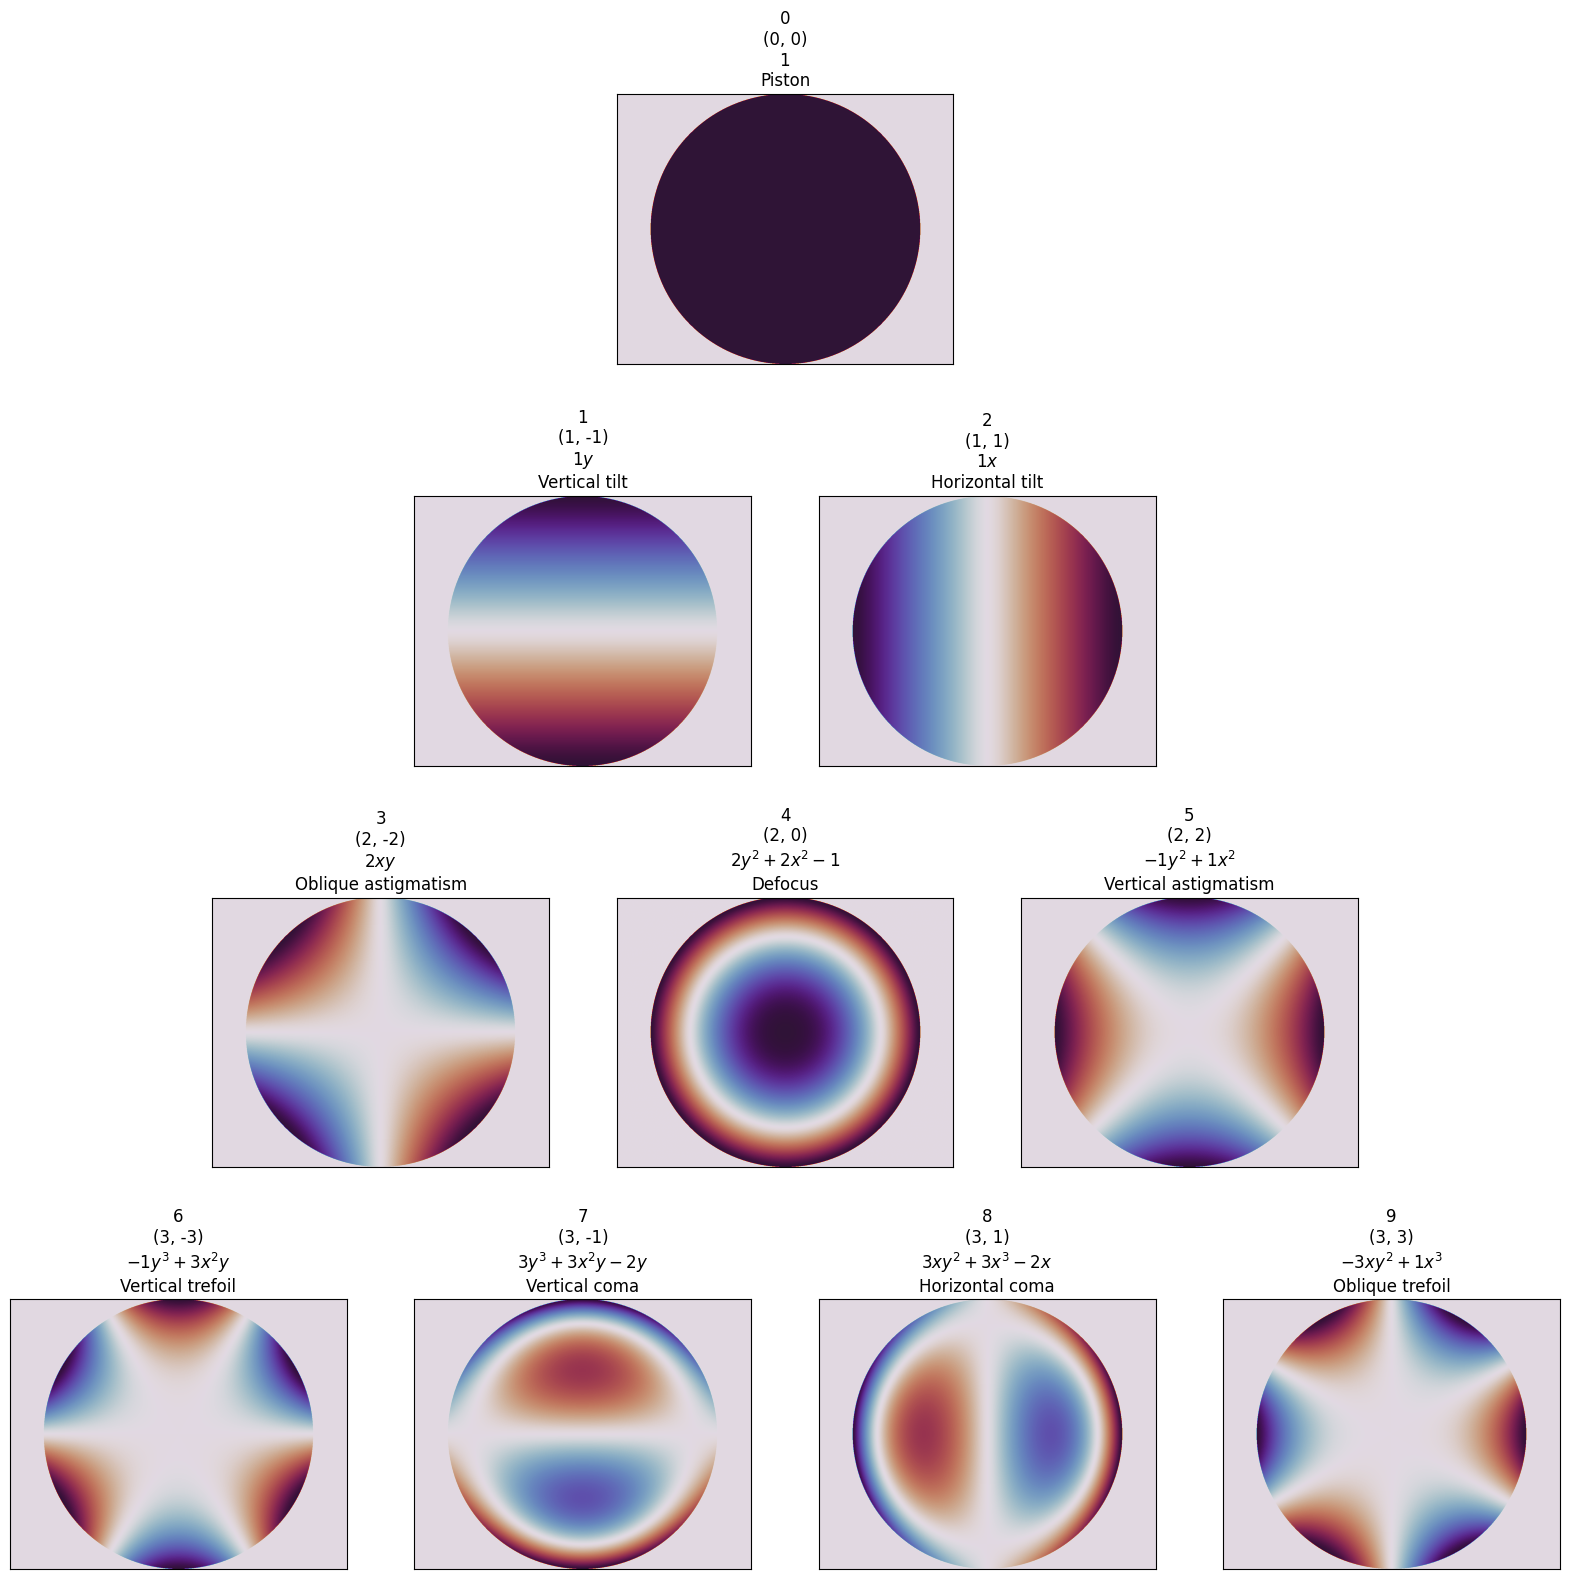

In [117]:
from slmsuite.holography.toolbox.phase import zernike_pyramid_plot

plt.figure(figsize=(20,20))
zernike_pyramid_plot(slm, order=3)

In [118]:
slm.get_source_center()

array([640, 511], dtype=int64)

In [119]:
plt.imshow(slm.source['amplitude'])

KeyError: 'amplitude'

In [178]:
from slmsuite.holography.toolbox.phase import zernike

zernke_42 = zernike(slm, 2)

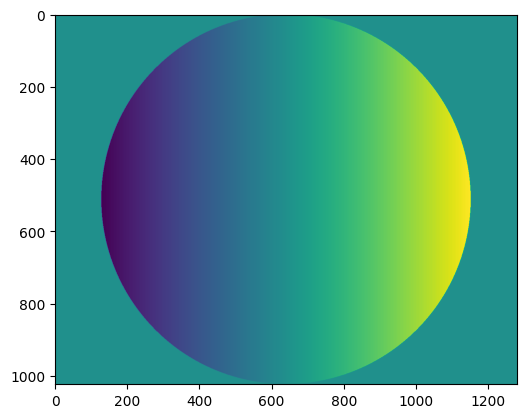

In [179]:
plt.imshow(zernke_42)

# test this peak detection from cgpt

In [ ]:
import numpy as np
from skimage.feature import peak_local_max

def refine_centers(image, expected_centers, patch_size=40, min_distance=1, threshold_abs=None):
    half = patch_size // 2
    refined_centers = []

    for (x_exp, y_exp) in expected_centers:
        x_exp, y_exp = int(round(x_exp)), int(round(y_exp))
        patch = image[y_exp - half:y_exp + half, x_exp - half:x_exp + half]

        # Detect all peaks in this patch
        peaks = peak_local_max(
            patch,
            min_distance=min_distance,
            threshold_abs=threshold_abs,
            num_peaks=1  # adjust if needed
        )

        if len(peaks) == 0:
            refined_centers.append((x_exp, y_exp))
            continue

        # Find the peak closest to the expected center (in patch coordinates)
        patch_center = np.array([half, half])
        distances = np.linalg.norm(peaks - patch_center, axis=1)
        closest_peak = peaks[np.argmin(distances)]

        # Convert local peak coords to global image coords
        y_actual = y_exp - half + closest_peak[0]
        x_actual = x_exp - half + closest_peak[1]

        refined_centers.append((x_actual, y_actual))

    return refined_centers
import numpy as np

def find_actual_centers(image, expected_centers, patch_size=20):
    half = patch_size // 2
    actual_centers = []

    for (x_exp, y_exp) in expected_centers:
        x_exp, y_exp = int(round(x_exp)), int(round(y_exp))
        patch = image[y_exp - half:y_exp + half, x_exp - half:x_exp + half]

        Y, X = np.indices(patch.shape)
        total = patch.sum()
        if total == 0:
            actual_centers.append((x_exp, y_exp))  # fallback
            continue

        x_center = (X * patch).sum() / total
        y_center = (Y * patch).sum() / total

        # Convert to global coordinates
        actual_x = x_exp - half + x_center
        actual_y = y_exp - half + y_center

        actual_centers.append((actual_x, actual_y))

    return actual_centers


In [3]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])

NameError: name 'fs' is not defined

In [4]:
spot_locations

NameError: name 'spot_locations' is not defined

In [157]:
refined_centres = refine_centers(loaded[5]["images"][0],spot_locations,40)

# Actual SLM

In [1]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb,g
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from src.algos import *
%load_ext autoreload
%autoreload 2

c:\Users\QC\Envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [2]:
fs = slm_initialise(force=True,verbose=True)

An error occurred with slm: 'NoneType' object has no attribute 'close'
An error occurred with cam: 'NoneType' object has no attribute 'close'
Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
TLCameraSDK initializing... success
Looking for cameras... success
ThorCam sn '12975' initializing... success


c:\Users\QC\Envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


array([[1, 1, 2, ..., 2, 2, 1],
       [2, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 2],
       ...,
       [1, 2, 1, ..., 2, 1, 1],
       [1, 3, 2, ..., 1, 2, 1],
       [2, 1, 1, ..., 1, 2, 2]], dtype=uint16)

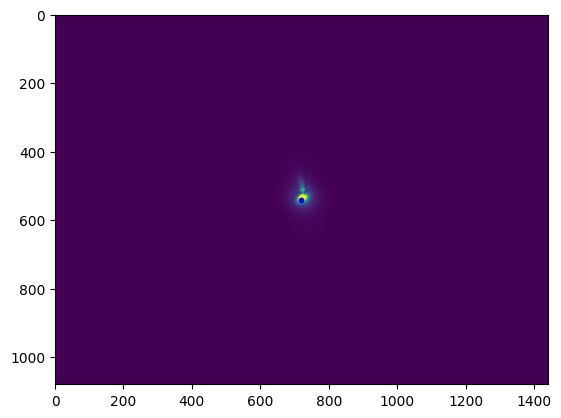

In [3]:
plot_cam(fs,phase="zero",centre=True, save=True)

smooth:   0%|          | 0/16 [00:00<?, ?it/s]

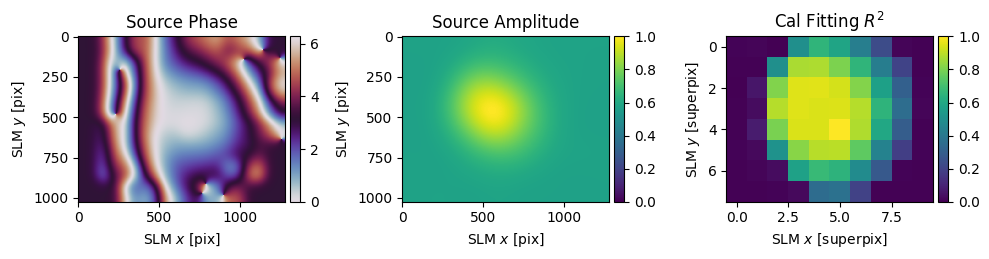

array([[2, 2, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 2, 1],
       ...,
       [1, 2, 1, ..., 1, 1, 2],
       [2, 2, 1, ..., 2, 1, 1],
       [1, 2, 1, ..., 2, 2, 1]], dtype=uint16)

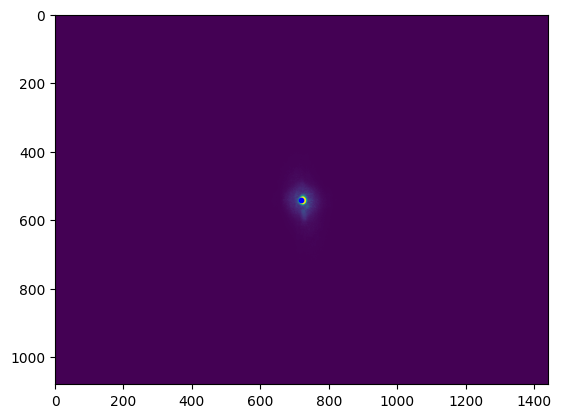

In [4]:
calibrate(fs,vendor = False,refresh = False)
sp_calibrate(fs,refresh=False)
plot_cam(fs,phase="zero",centre=True, save=True)

# Zernike testing

Iterate a single zernike polynomial and get the cam images
(shift the zernike polynomials to the slm centre)
visualise the plots to see the effect of aberration
calculate metric and visualise for convexity or atleast a minima

for a given zernike term
    for a given spot 
        find fit metrics (rmse error??)


In [10]:
base_phase = np.load(base_path/ 'data' / 'zernike' / 'raw' / 'spots_uc_32_spot_bb_phase.npy')

writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writing phase
writin

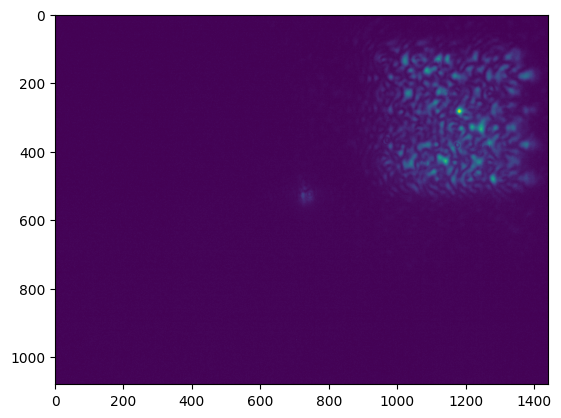

In [112]:
# base_phase = np.zeros(fs.slm.shape)
data = {}
zernike_indices = [i for i in range(3,50)]
for zernike_index in zernike_indices:
    zernike_term_phase = zernike(fs.slm, zernike_index)
    data[zernike_index] = {
        "w": [],
        "images": []
    }
    for w in np.linspace(-10, 10, 201):  
        phase = base_phase + w * zernike_term_phase
        image = save_cam(fs,phase = phase,sleep = 4)
        data[zernike_index]["w"].append(w)
        data[zernike_index]["images"].append(image)
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_100w.pkl"
with open(save_path, 'wb') as f:
    pickle.dump(data, f)


In [113]:
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_100w.pkl"
with open(save_path, 'rb') as f:
    loaded = pickle.load(f)

# Access:
loaded[7]["w"]
loaded[7]["images"][0]


array([[1, 2, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 2, 1, 1],
       [2, 1, 1, ..., 1, 2, 1],
       ...,
       [1, 1, 2, ..., 2, 2, 2],
       [1, 2, 1, ..., 1, 2, 1],
       [1, 1, 2, ..., 1, 2, 1]], dtype=uint16)

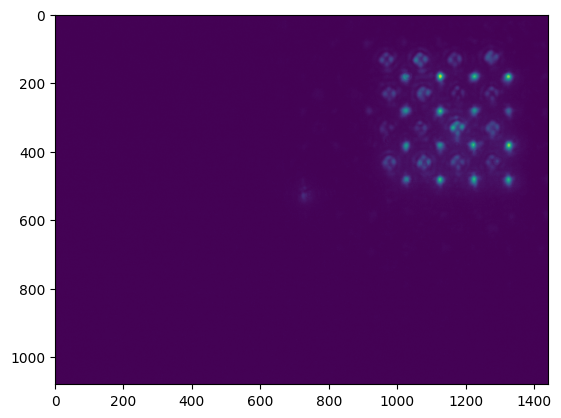

In [114]:
plt.imshow(loaded[5]["images"][19])

In [ ]:
from lmfit.models import Gaussian2dModel
import numpy as np

def get_tweezer_metrics(target, waist_multiplier=7):
    ny, nx = target.shape
    y, x = np.mgrid[:ny, :nx]
    x_flat = x.ravel()
    y_flat = y.ravel()
    z_flat = target.ravel()

    # Fit 2D Gaussian
    model = Gaussian2dModel()
    params = model.guess(z_flat, x=x_flat, y=y_flat)
    result = model.fit(z_flat, params, x=x_flat, y=y_flat, max_nfev=10000)

    # Best-fit parameters
    height = result.params["height"].value
    sigmax = result.params["sigmax"].value
    sigmay = result.params["sigmay"].value
    centerx = result.params["centerx"].value
    centery = result.params["centery"].value

    # Fit quality
    fitted = result.best_fit
    residuals = z_flat - fitted
    rmse = np.sqrt(np.mean(residuals**2))
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((z_flat - np.mean(z_flat))**2)
    r_squared = 1 - (ss_res / ss_tot)

    # FWHM and ellipticity
    fwhm_x = 2 * np.sqrt(2 * np.log(2)) * sigmax
    fwhm_y = 2 * np.sqrt(2 * np.log(2)) * sigmay
    ellipticity = sigmax / sigmay if sigmay != 0 else np.inf

    # === Strehl-style metric ===
    # Use window size based on waist multiplier (e.g., 5x or 7x waist)
    sigma_avg = (sigmax + sigmay) / 2
    window_size = int(round(waist_multiplier * sigma_avg))

    # Make sure it's odd (centered box)
    if window_size % 2 == 0:
        window_size += 1

    half = window_size // 2
    cx, cy = int(round(centerx)), int(round(centery))

    # Crop patch around fitted center
    y_start = max(cy - half, 0)
    y_end   = min(cy + half + 1, ny)
    x_start = max(cx - half, 0)
    x_end   = min(cx + half + 1, nx)

    patch = target[y_start:y_end, x_start:x_end]
    if patch.size > 0 and patch.sum() > 0:
        strehl_prime = patch.max() / patch.sum()
    else:
        strehl_prime = 0.0  # fallback in case of zero patch

    return {
        "height": height,
        "sigmax": sigmax,
        "sigmay": sigmay,
        "centerx": centerx,
        "centery": centery,
        "fwhm_x": fwhm_x,
        "fwhm_y": fwhm_y,
        "ellipticity": ellipticity,
        "strehl_prime": strehl_prime,
        "rmse": rmse,
        "r_squared": r_squared,
        "window_px": window_size
    }


In [508]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)])
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)])

In [47]:
refined_centres[0][1]
plt.imshow()

NameError: name 'refined_centres' is not defined

In [117]:
results = []
crop_pixels = 30

for zernike_index, zernike_data in loaded.items():
    images = zernike_data["images"]  # list of images at different w

    for w_index, image in enumerate(images):
        refined_centres = refine_centers(image, spot_locations, 200)
        for (expected, refined) in zip(spot_locations, refined_centres):
            cx, cy = refined
            crop_details = (
                slice(cy - crop_pixels, cy + crop_pixels),
                slice(cx - crop_pixels, cx + crop_pixels)
            )

            cropped_image = image[crop_details]
            metrics = get_tweezer_metrics(cropped_image)

            results.append({
                "zernike_index": zernike_index,
                "w_index": w_index,
                "w":zernike_data['w'][w_index],
                "expected_x": expected[0],
                "expected_y": expected[1],
                "refined_x": cx,
                "refined_y": cy,
                **metrics
            })



In [118]:
import pandas as pd
pdf = pd.DataFrame(results)

In [119]:
pdf[(pdf['w_index'] == 4)&(pdf['zernike_index'] == 7)&(pdf['expected_y']==180)]

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,height,sigmax,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
12928,7,4,-9.6,1030,180,1052,179,61.169684,8.567562,6.752292,29.970971,32.210136,20.175068,15.900432,1.268838,0.002371,3.830756,0.883761,55
12932,7,4,-9.6,1130,180,1151,180,104.458279,6.957566,6.550738,32.205212,30.193688,16.383815,15.425809,1.062104,0.003224,5.398941,0.908472,47
12936,7,4,-9.6,1230,180,1151,180,104.458279,6.957566,6.550738,32.205212,30.193688,16.383815,15.425809,1.062104,0.003224,5.398941,0.908472,47
12940,7,4,-9.6,1330,180,1350,179,113.773636,7.161409,6.692542,31.425531,31.937627,16.863831,15.759731,1.070058,0.003200,3.874243,0.963460,49


In [51]:
pdf[(pdf['zernike_index'] == 7)&(pdf['expected_y']==180)&(pdf['expected_x']==1030)]

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,height,sigmax,sigmay,centerx,centery,fwhm_x,fwhm_y,ellipticity,strehl_prime,rmse,r_squared,window_px
1920,7,0,0.000000,1030,180,1125,182,140.191790,5.633258,6.271790,30.615333,29.997931,13.265308,14.768937,0.898190,0.004133,4.439261,0.958723,43
1936,7,1,0.344828,1030,180,1124,181,140.909978,5.642965,6.254514,30.585943,31.050802,13.288167,14.728256,0.902223,0.004091,4.457284,0.958808,43
1952,7,2,0.689655,1030,180,1124,182,140.882305,5.647762,6.268966,29.742252,30.075870,13.299462,14.762287,0.900908,0.004161,4.445980,0.959099,43
1968,7,3,1.034483,1030,180,1123,181,139.855722,5.652258,6.264871,29.910403,31.130798,13.310051,14.752643,0.902215,0.004013,4.456801,0.958241,43
1984,7,4,1.379310,1030,180,1122,182,139.042313,5.664528,6.258125,29.851062,30.106225,13.338944,14.736758,0.905148,0.004147,4.439448,0.958128,43
2000,7,5,1.724138,1030,180,1121,182,138.161154,5.718981,6.245469,29.840166,30.133124,13.467171,14.706956,0.915701,0.004142,4.511519,0.956465,43
2016,7,6,2.068966,1030,180,1120,182,137.558798,5.730122,6.224471,30.111698,30.189091,13.493405,14.657510,0.920580,0.004102,4.522698,0.955800,43
2032,7,7,2.413793,1030,180,1119,182,136.548741,5.777526,6.209303,30.152740,30.220121,13.605034,14.621791,0.930463,0.004078,4.518129,0.955393,43
2048,7,8,2.758621,1030,180,1119,182,135.258773,5.831740,6.220841,29.173049,30.270878,13.732699,14.648962,0.937452,0.004050,4.481203,0.955762,43
2064,7,9,3.103448,1030,180,1118,181,134.259483,5.864163,6.245188,29.155345,31.317693,13.809048,14.706294,0.938989,0.004012,4.516727,0.954744,43


In [197]:
pdf['strehl_prime_scaled'] = pdf['strehl_prime']*200

<Axes: >

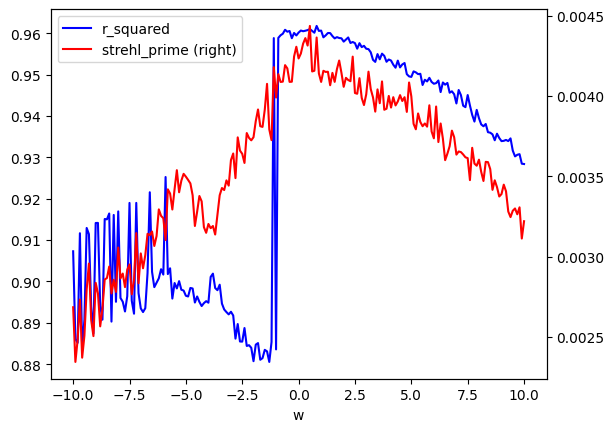

In [428]:
subset = pdf[
    (pdf['zernike_index'] == 7) &
    (pdf['expected_y'] == 180) &
    (pdf['expected_x'] == 1030)
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="strehl_prime", label="strehl_prime", color="red", ax=ax, secondary_y=True)

In [ ]:
#15 - 31 bad data or no trends
#35-37, 43-46 too many oscillations

{'height': 80.73212775567761,
 'sigmax': 6.763867516581283,
 'sigmay': 6.50473431040791,
 'centerx': 43.579810910779855,
 'centery': 42.18726084479169,
 'fwhm_x': 15.927690809979312,
 'fwhm_y': 15.317478741749117,
 'ellipticity': 1.039837631147939,
 'strehl_prime': 0.0036013523445538732,
 'rmse': 5.646980991164243,
 'r_squared': 0.7210885826707873,
 'window_px': 47}

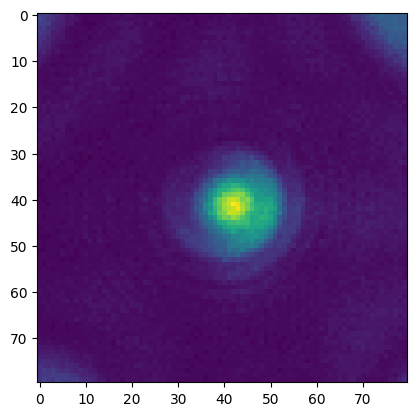

In [ ]:
zernike_index = 7
crop_pixels = 40
w =70
refined_centre = (1030,	180)
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])
get_tweezer_metrics(loaded[zernike_index]["images"][w][crop_details])



In [252]:
bb_locations

array([[ 980,  130],
       [ 980,  230],
       [ 980,  330],
       [ 980,  430],
       [1080,  130],
       [1080,  230],
       [1080,  330],
       [1080,  430],
       [1180,  130],
       [1180,  230],
       [1180,  330],
       [1180,  430],
       [1280,  130],
       [1280,  230],
       [1280,  330],
       [1280,  430]])

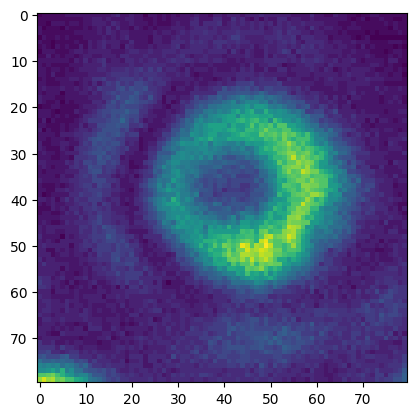

In [306]:
crop_pixels = 40
refined_centre = (1091, 134)
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[7]["images"][1][crop_details])

In [390]:
import numpy as np
from scipy import ndimage as ndi
from scipy.signal import fftconvolve

# ----------------------- utilities -----------------------

def robust_norm(patch):
    """Robustly normalize to ~zero-mean, unit-scale using MAD."""
    med = np.median(patch)
    mad = np.median(np.abs(patch - med)) + 1e-9
    z = (patch - med) / (1.4826 * mad)
    return z.astype(np.float32)

def crop_patch_centered(img, y, x, half):
    """
    Return a (2*half+1, 2*half+1) patch centered on (y,x).
    Reflect-pads if near borders so the patch stays centered.
    """
    H, W = img.shape
    size = 2*half + 1
    y1, y2 = y - half, y + half + 1
    x1, x2 = x - half, x + half + 1

    pad_top    = max(0, -y1)
    pad_bottom = max(0, y2 - H)
    pad_left   = max(0, -x1)
    pad_right  = max(0, x2 - W)

    y1c, y2c = max(0, y1), min(H, y2)
    x1c, x2c = max(0, x1), min(W, x2)
    patch = img[y1c:y2c, x1c:x2c]

    if pad_top or pad_bottom or pad_left or pad_right:
        patch = np.pad(patch, ((pad_top, pad_bottom), (pad_left, pad_right)), mode='reflect')

    # ensure exact shape (can happen if image is tiny)
    patch = patch[:size, :size]
    return patch

def ring_kernel(radius, thickness=3, center_frac=0.45):
    """
    Build a zero-mean, unit-energy ring template:
      +1 on an annulus at 'radius' (±thickness/2),
      -1 in a central disk of radius = center_frac * radius,
    normalized so sum=0 and ||K||_2 = 1. (Good for NCC-like scoring.)
    """
    r  = float(radius)
    t  = float(thickness)
    rc = max(1.0, center_frac * r)

    size = int(np.ceil(2*(r + t) + 5))  # generous margin, odd
    if size % 2 == 0: size += 1
    c = size // 2

    yy, xx = np.mgrid[0:size, 0:size]
    rr = np.sqrt((yy - c)**2 + (xx - c)**2)

    ring  = (np.abs(rr - r) <= (t/2.0)).astype(np.float32)
    center = (rr <= rc).astype(np.float32)

    # Zero-mean by balancing areas
    Ar = ring.sum() + 1e-9
    Ac = center.sum() + 1e-9
    ker = (ring / Ar) - (center / Ac)

    # Unit L2-norm
    ker /= np.sqrt((ker**2).sum() + 1e-12)
    return ker

def quad_peak_subpixel(Z):
    """Sub-pixel peak from a 2D quadratic fit around the discrete maximum."""
    h, w = Z.shape
    cy, cx = h//2, w//2
    y, x = np.mgrid[-cy:h-cy, -cx:w-cx]
    A = np.column_stack([x*x, y*y, x*y, x, y, np.ones_like(x)])
    b = Z.reshape(-1, 1)
    try:
        coef, *_ = np.linalg.lstsq(A, b, rcond=None)
        a, b2, c, d, e, f = coef.flatten()
        det = 4*a*b2 - c*c
        if abs(det) < 1e-10:
            return 0.0, 0.0
        x0 = (c*e - 2*b2*d) / det
        y0 = (c*d - 2*a*e) / det
        # clamp within window
        return float(np.clip(y0, -cy, cy)), float(np.clip(x0, -cx, cx))
    except np.linalg.LinAlgError:
        return 0.0, 0.0

def ringness_metrics(patch, cy, cx, r_best, thickness=3, center_frac=0.45):
    """
    Compute bottle-ness:
      - I_center: mean in disk of radius rc
      - I_ring:   mean in annulus |r - r_best| <= t/2
      - I_bg:     mean in outer annulus [r_best+1.5t, r_best+3t]
    Returns: contrast = I_ring - I_center, ratio = I_ring / (I_center+eps), snr = (I_ring - I_bg)/std
    """
    H, W = patch.shape
    yy, xx = np.mgrid[0:H, 0:W]
    rr = np.sqrt((yy - cy)**2 + (xx - cx)**2)
    t = float(thickness)
    rc = max(1.0, center_frac * float(r_best))

    center_mask = (rr <= rc)
    ring_mask   = (np.abs(rr - r_best) <= (t/2.0))
    bg_mask     = (rr >= (r_best + 1.5*t)) & (rr <= (r_best + 3.0*t))

    if not np.any(center_mask) or not np.any(ring_mask):
        return 0.0, 1.0, 0.0, np.nan, np.nan, np.nan

    I_center = float(patch[center_mask].mean())
    I_ring   = float(patch[ring_mask].mean())
    I_bg     = float(patch[bg_mask].mean()) if np.any(bg_mask) else float(np.median(patch))

    contrast = I_ring - I_center
    ratio    = I_ring / (I_center + 1e-6)
    snr      = (I_ring - I_bg) / (patch.std() + 1e-6)
    return contrast, ratio, snr, I_center, I_ring, I_bg

# ----------------------- main function -----------------------

def refine_bottle_centers(
    image,
    expected_centers_xy,
    patch_half=40,                 # half-size of patch; should exceed max radius + margins
    radii=(6, 24),                 # search radii range (pixels)
    radius_step=1,
    thickness=3,                   # ring thickness (pixels)
    center_frac=0.45,              # central "dark core" radius ~ fraction of ring radius
    ring_contrast_thresh=0.03,     # absolute contrast (on normalized patch)
    ring_ratio_thresh=1.15,        # I_ring / I_center must exceed this
    snr_thresh=1.2,                # ring vs bg SNR
    subpix_window=5,               # odd window for quadratic fit
    use_fft=True
):
    """
    Args:
      image: 2D numpy array (grayscale). If RGB, pass image.mean(axis=-1).
      expected_centers_xy: list/array of (x, y) guesses (note: x=col, y=row).
    Returns:
      refined_xy: (N,2) subpixel (x,y)
      is_bottle:  (N,) boolean mask (True = passes ringness test)
      info: dict of arrays: best_radius, contrast, ratio, snr
    """
    img = np.asarray(image, dtype=np.float32)
    if img.ndim == 3:
        img = (0.2989*img[...,0] + 0.5870*img[...,1] + 0.1140*img[...,2]).astype(np.float32)
    H, W = img.shape

    # Prebuild kernels for all radii
    R_list = list(range(int(radii[0]), int(radii[1]) + 1, int(max(1, radius_step))))
    kernels = [ring_kernel(r, thickness=thickness, center_frac=center_frac) for r in R_list]

    refined_xy = []
    is_bottle  = []
    best_radii = []
    contrasts  = []
    ratios     = []
    snrs       = []

    hw = subpix_window // 2

    for (x_exp, y_exp) in np.asarray(expected_centers_xy, dtype=float):
        y0 = int(round(y_exp))
        x0 = int(round(x_exp))

        # Extract patch centered at expected location; robustly normalize
        patch = crop_patch_centered(img, y0, x0, patch_half)
        patch_n = robust_norm(patch)

        # Bandpass a bit to emphasize rings (optional but helpful)
        # (LoG-like) small-scale emphasis; keep amplitude similar
        patch_bp = patch_n - ndi.gaussian_filter(patch_n, sigma=6)

        # Template matching across radii
        best_score = -1e9
        best_yx = (patch_half, patch_half)
        best_r  = None
        best_resp_map = None

        for r, ker in zip(R_list, kernels):
            # correlate
            if use_fft:
                resp = fftconvolve(patch_bp, ker[::-1, ::-1], mode='same')  # correlation via conv with flipped ker
            else:
                resp = ndi.correlate(patch_bp, ker, mode='reflect')
            # take the local max near the center (rings should be close to expected)
            # search window ±(patch_half//2)
            y1 = patch_half - (patch_half//2)
            y2 = patch_half + (patch_half//2) + 1
            x1 = y1
            x2 = y2
            win = resp[y1:y2, x1:x2]
            iy, ix = np.unravel_index(np.argmax(win), win.shape)
            py, px = y1 + iy, x1 + ix

            score = resp[py, px]
            if score > best_score:
                best_score = score
                best_yx = (py, px)
                best_r = r
                best_resp_map = resp

        # Subpixel refinement on the response map
        py, px = best_yx
        yA, yB = max(hw, py)-hw, min(best_resp_map.shape[0]-hw, py+1+hw)
        xA, xB = max(hw, px)-hw, min(best_resp_map.shape[1]-hw, px+1+hw)
        Z = best_resp_map[yA:yB, xA:xB]
        if Z.shape[0] >= 2*hw+1 and Z.shape[1] >= 2*hw+1:
            dy, dx = quad_peak_subpixel(Z)
            sub_y = (yA + Z.shape[0]//2) + dy
            sub_x = (xA + Z.shape[1]//2) + dx
        else:
            sub_y, sub_x = float(py), float(px)

        # Bottle-vs-tweezer test by ringness metrics on the ORIGINAL (not bandpassed) patch
        contrast, ratio, snr, I_c, I_r, I_bg = ringness_metrics(
            patch, sub_y, sub_x, best_r, thickness=thickness, center_frac=center_frac
        )
        accepted = (contrast >= ring_contrast_thresh) and (ratio >= ring_ratio_thresh) and (snr >= snr_thresh)

        # Map back to global image coords (patch is centered at y0,x0)
        y_ref = y0 + (sub_y - patch_half)
        x_ref = x0 + (sub_x - patch_half)

        refined_xy.append([x_ref, y_ref])
        is_bottle.append(accepted)
        best_radii.append(best_r if best_r is not None else np.nan)
        contrasts.append(contrast)
        ratios.append(ratio)
        snrs.append(snr)

    refined_xy = np.asarray(refined_xy, dtype=np.int32)
    is_bottle  = np.asarray(is_bottle, dtype=bool)
    info = {
        "best_radius": np.asarray(best_radii, dtype=np.float32),
        "contrast":    np.asarray(contrasts, dtype=np.float32),
        "ratio":       np.asarray(ratios, dtype=np.float32),
        "snr":         np.asarray(snrs, dtype=np.float32),
    }
    return refined_xy, is_bottle, info


In [391]:
bb_locations

array([[ 980,  130],
       [ 980,  230],
       [ 980,  330],
       [ 980,  430],
       [1080,  130],
       [1080,  230],
       [1080,  330],
       [1080,  430],
       [1180,  130],
       [1180,  230],
       [1180,  330],
       [1180,  430],
       [1280,  130],
       [1280,  230],
       [1280,  330],
       [1280,  430]])

In [545]:
refined_centres,is_bottle,info = refine_bottle_centers(loaded[7]["images"][1],bb_locations)

In [546]:
refined_centres

array([[ 994,  131],
       [1000,  231],
       [ 993,  333],
       [1000,  433],
       [1095,  131],
       [1100,  231],
       [1094,  332],
       [1100,  431],
       [1195,  132],
       [1200,  230],
       [1200,  331],
       [1200,  431],
       [1300,  125],
       [1300,  231],
       [1300,  331],
       [1300,  431]])

In [394]:
bb_locations

array([[ 980,  130],
       [ 980,  230],
       [ 980,  330],
       [ 980,  430],
       [1080,  130],
       [1080,  230],
       [1080,  330],
       [1080,  430],
       [1180,  130],
       [1180,  230],
       [1180,  330],
       [1180,  430],
       [1280,  130],
       [1280,  230],
       [1280,  330],
       [1280,  430]])

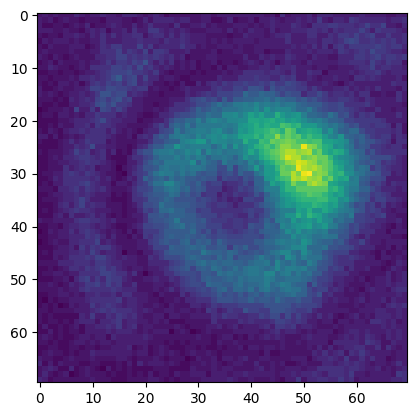

In [423]:
crop_pixels = 35
refined_centre = refined_centres[5]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[7]["images"][1][crop_details])

{'height': 18.639300830714223,
 'sigmax': 21.63552976381632,
 'sigmay': 19.124297030928453,
 'centerx': 44.10374404065087,
 'centery': 31.485248016537778,
 'fwhm_x': 50.94777917269839,
 'fwhm_y': 45.03427799555619,
 'ellipticity': 1.1313111132308087,
 'strehl_prime': 0.0008903177939903549,
 'rmse': 3.713752980858549,
 'r_squared': 0.5720951435228543,
 'window_px': 143}

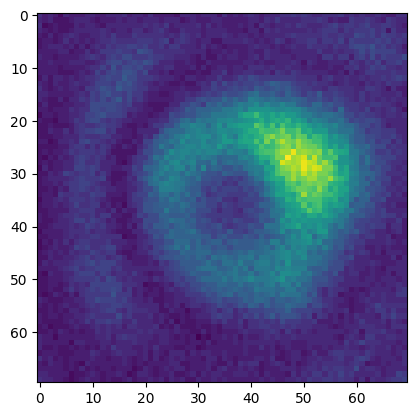

In [431]:
zernike_index = 7
crop_pixels = 35
w = 0
refined_centre =refined_centres[5]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])
get_tweezer_metrics(loaded[zernike_index]["images"][w][crop_details])


In [698]:
import numpy as np
from scipy.optimize import curve_fit, least_squares
from scipy.ndimage import map_coordinates

# ----------------------------------
# Bottle-beam model with OFFSET
# ----------------------------------
def bb(x, y, A, w, xc, yc, B):
    r = np.sqrt((x - xc)**2 + (y - yc)**2)
    return B + A * (r**4) * np.exp(-(r**2)/(w**2))

# ------------- helpers -------------
def _robust_norm(p):
    p = np.asarray(p, dtype=np.float32)
    p1, p99 = np.percentile(p, [1, 99])
    if p99 <= p1: p1, p99 = float(p.min()), float(p.max())
    q = (p - p1) / (p99 - p1 + 1e-9)
    return np.clip(q, 0, 1).astype(np.float32)

def _radial_profile(img, cy, cx, nbins=240, rmax=None):
    H, W = img.shape
    yy, xx = np.mgrid[0:H, 0:W]
    rr = np.sqrt((yy - cy)**2 + (xx - cx)**2)
    if rmax is None: rmax = min(H, W)/2 - 1
    bins = np.linspace(0, rmax, nbins+1)
    idx = np.clip(np.digitize(rr.ravel(), bins)-1, 0, nbins-1)
    prof = np.zeros(nbins, dtype=np.float64)
    counts = np.bincount(idx, minlength=nbins)
    sums   = np.bincount(idx, weights=img.ravel(), minlength=nbins)
    prof[counts>0] = sums[counts>0] / counts[counts>0]
    rc = 0.5*(bins[:-1] + bins[1:])
    return rc, prof

def _model_fwhm_for_w(w):
    # FWHM of r^4 exp(-r^2/w^2) above the OFFSET baseline:
    # solve s^2 e^{-s} = 2 e^{-2} for s=(r/w)^2; FWHM = w(√s2 - √s1)
    from math import sqrt, e
    from scipy.optimize import brentq
    c = 2.0 * (e**-2)
    f = lambda s: (s**2) * np.exp(-s) - c
    s1 = brentq(f, 1e-9, 2.0 - 1e-6)
    s2 = brentq(f, 2.0 + 1e-6, 10.0)
    return w * (sqrt(s2) - sqrt(s1))

def _sample_circle(img, cy, cx, r, ntheta=360):
    theta = np.linspace(0, 2*np.pi, ntheta, endpoint=False)
    yy = cy + r*np.sin(theta)
    xx = cx + r*np.cos(theta)
    vals = map_coordinates(img, [yy, xx], order=1, mode='reflect')
    return vals, theta

def _escape_intensity(img, cy, cx, r0, band_half, ntheta=360, r_step=0.5, center_radius=None):
    H, W = img.shape
    rmax_patch = min(H, W)/2 - 1
    r1 = max(0.0, r0 - band_half)
    r2 = min(rmax_patch, r0 + band_half)
    r_grid = np.arange(r1, r2 + 1e-6, r_step)
    if center_radius and center_radius > 0:
        YY, XX = np.mgrid[0:H, 0:W]
        RR = np.sqrt((YY - cy)**2 + (XX - cx)**2)
        I_center = float(img[RR <= center_radius].mean())
    else:
        I_center = float(img[int(round(cy)), int(round(cx))])

    best = (np.inf, 0.0, r0)
    for k in range(ntheta):
        th = 2*np.pi*k/ntheta
        yy = cy + r_grid*np.sin(th)
        xx = cx + r_grid*np.cos(th)
        vals = map_coordinates(img, [yy, xx], order=1, mode='reflect')
        imax = int(np.argmax(vals))
        barrier = float(vals[imax] - I_center)
        if barrier < best[0]:
            best = (barrier, th, float(r_grid[imax]))
    barrier, th, r_at = best
    return float(barrier), float(np.degrees(th)), r_at

# ------------- main -------------
def get_bottle_metrics(
    cropped_image,
    nbins_profile=240,
    center_frac=0.35,
    ntheta_uniformity=360,
    ntheta_escape=360,
    escape_r_step=0.5,
    waist_multiplier=7,
    use_lmfit=False   # if True and lmfit is available, it will try it first
):
    """
    Fits: I(x,y) = B + A * r^4 * exp(-r^2 / w^2)  (A,w,xc,yc,B)
    with SciPy by default; robust fallback to soft-L1. Then computes metrics.
    """
    img = np.asarray(cropped_image, dtype=np.float32)
    if img.ndim == 3:
        img = (0.2989*img[...,0] + 0.5870*img[...,1] + 0.1140*img[...,2]).astype(np.float32)

    patch = _robust_norm(img)
    H, W = patch.shape
    cy0 = (H - 1)/2.0
    cx0 = (W - 1)/2.0

    # Initials from radial profile
    rmax = min(H, W)/2 - 1
    r, prof = _radial_profile(patch, cy0, cx0, nbins=nbins_profile, rmax=rmax)
    start = max(3, int(0.05*len(r)))
    kpk = start + int(np.argmax(prof[start:]))
    r0_hint = float(r[kpk])
    w0 = max(1e-3, r0_hint/np.sqrt(2.0))  # r_peak = √2 w
    B0 = float(np.median(patch))
    # closed-form A0 for (w0,cx0,cy0,B0)
    YY, XX = np.mgrid[0:H, 0:W]
    rr = np.sqrt((XX - cx0)**2 + (YY - cy0)**2)
    phi = (rr**4) * np.exp(-(rr**2)/(w0**2))
    y = (patch - B0).ravel()
    A0 = float((y @ phi.ravel()) / (phi.ravel() @ phi.ravel() + 1e-12))
    p0 = [max(A0, 1e-6), w0, cx0, cy0, B0]

    # Bounds
    pad = 0.35 * min(H, W)
    B_lo = float(patch.min() - 0.2)
    B_hi = float(patch.max() + 0.2)
    bounds = (
        [0.0, 1e-6, cx0 - pad, cy0 - pad, B_lo],
        [np.inf, np.inf, cx0 + pad, cy0 + pad, B_hi]
    )

    A, w, cx, cy, B = p0
    fit_method = "scipy"

    # Prefer lmfit only if requested and available; else SciPy
    if use_lmfit:
        try:
            import lmfit
            m = lmfit.Model(lambda x, y, A, w, xc, yc, B: bb(x, y, A, w, xc, yc, B))
            pars = m.make_params(A=A, w=w, xc=cx, yc=cy, B=B)
            pars['A'].min = 0.0
            pars['w'].min = 1e-6
            pars['xc'].min, pars['xc'].max = cx0 - pad, cx0 + pad
            pars['yc'].min, pars['yc'].max = cy0 - pad, cy0 + pad
            pars['B'].min,  pars['B'].max  = B_lo, B_hi
            res = m.fit(patch, x=XX, y=YY, params=pars, method='least_squares', max_nfev=20000)
            A, w, cx, cy, B = [float(res.params[k].value) for k in ('A','w','xc','yc','B')]
            fit_method = "lmfit"
        except Exception:
            pass  # fall through to SciPy

    if fit_method != "lmfit":
        try:
            xdata = np.vstack([XX.ravel(), YY.ravel()])
            popt, _ = curve_fit(
                lambda XY, A, w, xc, yc, B: bb(XY[0], XY[1], A, w, xc, yc, B).ravel(),
                xdata, patch.ravel(), p0=p0, bounds=bounds, maxfev=30000
            )
            A, w, cx, cy, B = [float(v) for v in popt]
        except Exception:
            # robust fallback: soft-L1 least squares
            def resid(p):
                A_, w_, xc_, yc_, B_ = p
                return (bb(XX, YY, max(A_,0.0), max(w_,1e-6), xc_, yc_, B_) - patch).ravel()
            rs = least_squares(resid, p0, bounds=bounds, loss='soft_l1', f_scale=0.1, max_nfev=30000)
            A, w, cx, cy, B = [float(v) for v in rs.x]
            fit_method = "scipy_soft_l1"

    # Fit quality
    model = bb(XX, YY, A, w, cx, cy, B)
    resid = (patch - model).ravel()
    rmse = float(np.sqrt(np.mean(resid**2)))
    ss_res = float(np.sum(resid**2))
    ss_tot = float(np.sum((patch.ravel() - patch.mean())**2) + 1e-12)
    r2 = 1.0 - ss_res/ss_tot

    # Derived geometry from fitted w
    r_peak = float(np.sqrt(2.0) * w)
    fwhm = float(_model_fwhm_for_w(w))

    # Regions & stats (use fitted center)
    RR = np.sqrt((XX - cx)**2 + (YY - cy)**2)
    r_center = max(1.0, center_frac * r_peak)
    band_half = 0.5 * fwhm

    center_mask = RR <= r_center
    ring_mask   = np.abs(RR - r_peak) <= band_half
    bg_mask     = (RR >= r_peak + 1.5*band_half) & (RR <= r_peak + 3.0*band_half)

    I_center = float(patch[center_mask].mean()) if np.any(center_mask) else 0.0
    I_ring   = float(patch[ring_mask].mean())   if np.any(ring_mask)   else float(model[ring_mask].mean())
    I_bg     = float(patch[bg_mask].mean())     if np.any(bg_mask)     else float(np.median(patch))
    std_bg   = float(patch[bg_mask].std()+1e-6) if np.any(bg_mask)     else float(patch.std()+1e-6)

    contrast = (I_ring - I_center) / (I_ring + 1e-9)
    center_suppression = I_center / (I_ring + 1e-9)
    snr_rb = (I_ring - I_bg) / std_bg

    # Uniformity & escape
    vals_ring, _ = _sample_circle(patch, cy, cx, r_peak, ntheta=ntheta_uniformity)
    uniformity_std_pct = 100.0 * (vals_ring.std() / (vals_ring.mean() + 1e-9))

    escape_I, escape_theta_deg, escape_r = _escape_intensity(
        patch, cy, cx, r_peak, band_half, ntheta=ntheta_escape, r_step=escape_r_step, center_radius=r_center
    )

    # Cleanliness / encircled energy (normalized profile)
    r_prof, prof = _radial_profile(patch, cy, cx, nbins=nbins_profile, rmax=rmax)
    beyond = r_prof >= (r_peak + fwhm)
    outer_ring_ratio = float(prof[beyond].max() / (I_ring + 1e-9)) if np.any(beyond) else 0.0
    Er = 2*np.pi * r_prof * prof
    m_band = (r_prof >= (r_peak - band_half)) & (r_prof <= (r_peak + band_half))
    E_band = np.trapz(Er[m_band], r_prof[m_band]) if np.any(m_band) else 0.0
    E_tot  = np.trapz(Er, r_prof) + 1e-12
    encircled_energy_in_ring = float(E_band / E_tot)

    # Strehl-like (comparable to your tweezer metric)
    sigma_like = max(fwhm/2.355, 1.0)
    window_size = int(round(waist_multiplier * sigma_like))
    if window_size % 2 == 0: window_size += 1
    half = window_size // 2
    y0, y1 = int(max(cy - half, 0)), int(min(cy + half + 1, H))
    x0, x1 = int(max(cx - half, 0)), int(min(cx + half + 1, W))
    box = patch[y0:y1, x0:x1]
    strehl_prime = float(box.max() / (box.sum() + 1e-12)) if box.size else 0.0

    # Analytical derivatives at r=0 for I=B + A r^4 e^{-r^2/w^2}
    d2I_dr2_at0 = 0.0
    d4I_dr4_at0 = float(24.0 * A)

    return {
        # fitted params (offset included)
        "A": float(A), "w_px": float(w), "offset": float(B),
        "centerx": float(cx), "centery": float(cy),
        "fit_method": fit_method, "rmse": float(rmse), "r_squared": float(r2),

        # derived geometry
        "r_peak_px": r_peak, "fwhm_px": fwhm,

        # intensities & SNR
        "I_center": I_center, "I_ring": I_ring, "I_bg": I_bg,
        "contrast": contrast, "center_suppression": center_suppression, "snr_rb": snr_rb,

        # ring uniformity & escape
        "uniformity_std_pct": uniformity_std_pct,
        "escape_intensity": escape_I,
        "escape_theta_deg": escape_theta_deg,
        "escape_radius_px": escape_r,

        # cleanliness
        "outer_ring_ratio": outer_ring_ratio,
        "encircled_energy_in_ring": encircled_energy_in_ring,

        # strehl-like
        "strehl_prime": strehl_prime, "window_px": int(window_size),

        # model derivatives at origin
        "d2I_dr2_at0": d2I_dr2_at0, "d4I_dr4_at0": d4I_dr4_at0,
    }


{'A': 0.00021575500675267783,
 'w_px': 8.805611103186797,
 'offset': 0.08528898781001425,
 'centerx': 34.88168963672068,
 'centery': 34.85735032185627,
 'fit_method': 'scipy',
 'rmse': 0.10315216801188756,
 'r_squared': 0.8124862317285118,
 'r_peak_px': 12.45301464710988,
 'fwhm_px': 10.268370773212563,
 'I_center': 0.2430826872587204,
 'I_ring': 0.657463014125824,
 'I_bg': 0.11275503039360046,
 'contrast': 0.6302716918423165,
 'center_suppression': 0.36972830663668543,
 'snr_rb': 6.261528832806869,
 'uniformity_std_pct': 29.512425527777296,
 'escape_intensity': 0.13229317963123322,
 'escape_theta_deg': 70.0,
 'escape_radius_px': 16.8188292605036,
 'outer_ring_ratio': 0.2339097400504109,
 'encircled_energy_in_ring': 0.5542784347429376,
 'strehl_prime': 0.001768005785729868,
 'window_px': 31,
 'd2I_dr2_at0': 0.0,
 'd4I_dr4_at0': 0.005178120162064268}

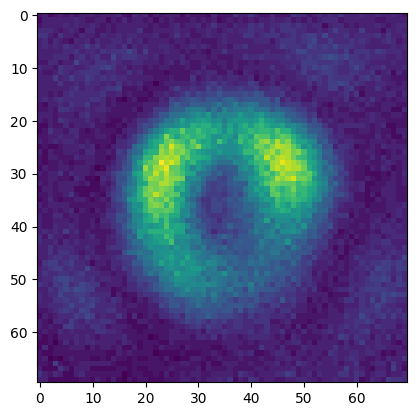

In [699]:
zernike_index = 4
crop_pixels = 35
w = 100
refined_centres,is_bottle,info = refine_bottle_centers(loaded[zernike_index]["images"][w],bb_locations)
refined_centre =refined_centres[5]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])
get_bottle_metrics(loaded[zernike_index]["images"][w][crop_details])

In [720]:
results = []
crop_pixels = 35

for zernike_index, zernike_data in loaded.items():
    images = zernike_data["images"]
    for w_index, image in enumerate(images):
        refined_centres,is_bottle,info = refine_bottle_centers(loaded[zernike_index]["images"][w_index],bb_locations)
        for (expected, refined) in zip(bb_locations, refined_centres):
            cx, cy = refined  # (x, y)
            crop = (
                slice(int(cy - crop_pixels), int(cy + crop_pixels)),
                slice(int(cx - crop_pixels), int(cx + crop_pixels)),
            )
            cropped = image[crop]
            metrics = get_bottle_metrics(cropped)
            results.append({
                "zernike_index": zernike_index,
                "w_index": w_index,
                "w": zernike_data['w'][w_index],
                "expected_x": expected[0],
                "expected_y": expected[1],
                "refined_x": float(cx),
                "refined_y": float(cy),
                **metrics
            })


ValueError: attempt to get argmax of an empty sequence

In [ ]:
pdf_bb = pd.DataFrame(results)

In [709]:
pdf_bb

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,A,w_px,offset,...,uniformity_std_pct,escape_intensity,escape_theta_deg,escape_radius_px,outer_ring_ratio,encircled_energy_in_ring,strehl_prime,window_px,d2I_dr2_at0,d4I_dr4_at0
0,3,80,-2.0,980,130,970.0,133.0,0.000192,9.256999,0.106588,...,12.732630,0.438789,85.0,13.194002,0.228350,0.571560,0.001463,33,0.0,0.004605
1,3,80,-2.0,980,230,978.0,232.0,0.000203,8.996592,0.091935,...,22.015939,0.207300,72.0,17.477564,0.196894,0.558815,0.001705,31,0.0,0.004870
2,3,80,-2.0,980,330,968.0,333.0,0.000174,8.944317,0.108704,...,36.676139,0.146277,275.0,15.434115,0.304115,0.523270,0.001942,31,0.0,0.004188
3,3,80,-2.0,980,430,977.0,433.0,0.000188,9.189989,0.141101,...,13.129047,0.337426,36.0,11.638307,0.264624,0.515074,0.001399,33,0.0,0.004509
4,3,80,-2.0,1080,130,1069.0,133.0,0.000184,9.265948,0.068280,...,19.295446,0.457243,267.0,14.701441,0.179065,0.609102,0.001600,33,0.0,0.004413
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3275,7,120,2.0,1180,430,1172.0,432.0,0.000157,9.252606,0.098557,...,30.225599,0.287027,66.0,14.690351,0.226818,0.555118,0.001752,33,0.0,0.003759
3276,7,120,2.0,1280,130,1271.0,125.0,0.000235,8.562407,0.081121,...,26.321149,0.124189,287.0,9.616689,0.246881,0.530291,0.001818,31,0.0,0.005628
3277,7,120,2.0,1280,230,1273.0,232.0,0.000143,9.542606,0.107002,...,22.796612,0.363895,84.0,13.431387,0.247963,0.583812,0.001690,33,0.0,0.003434
3278,7,120,2.0,1280,330,1274.0,333.0,0.000193,8.989174,0.102463,...,22.933467,0.243425,283.0,15.471398,0.222585,0.540776,0.001779,31,0.0,0.004628


<Axes: >

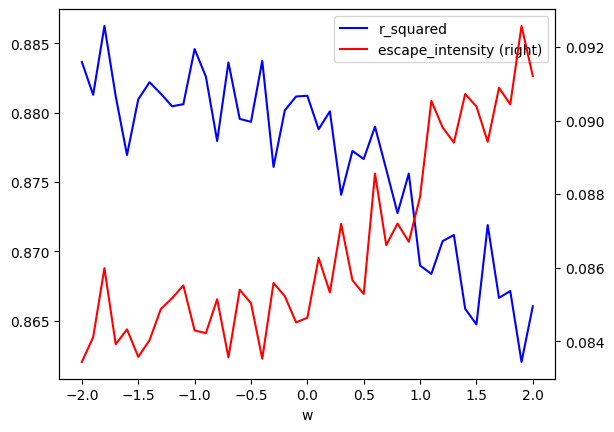

In [719]:
subset = pdf_bb[
    (pdf_bb['zernike_index'] == 7) &
    (pdf_bb['expected_y'] == 430) &
    (pdf_bb['expected_x'] == 980)
]

ax = subset.plot(x="w", y="r_squared", label="r_squared", color="blue")
subset.plot(x="w", y="rmse", label="escape_intensity", color="red", ax=ax, secondary_y=True)

In [711]:
pdf_bb[
    (pdf_bb['zernike_index'] == 6) &
    (pdf_bb['expected_y'] == 130) &
    (pdf_bb['expected_x'] == 980)
]

,zernike_index,w_index,w,expected_x,expected_y,refined_x,refined_y,A,w_px,offset,...,uniformity_std_pct,escape_intensity,escape_theta_deg,escape_radius_px,outer_ring_ratio,encircled_energy_in_ring,strehl_prime,window_px,d2I_dr2_at0,d4I_dr4_at0
1968,6,80,-2.0,980,130,970.0,132.0,0.000182,9.303857,0.098953,...,14.561471,0.433740,72.0,16.232949,0.226568,0.572381,0.001531,33,0.0,0.004358
1984,6,81,-1.9,980,130,970.0,132.0,0.000190,9.308962,0.101170,...,12.065042,0.527702,280.0,15.737192,0.228357,0.572367,0.001469,33,0.0,0.004553
2000,6,82,-1.8,980,130,970.0,132.0,0.000182,9.311812,0.097460,...,13.991317,0.449772,74.0,12.239560,0.217188,0.573830,0.001529,33,0.0,0.004360
2016,6,83,-1.7,980,130,970.0,132.0,0.000190,9.310094,0.101196,...,13.092314,0.528144,292.0,15.738133,0.239758,0.572902,0.001463,33,0.0,0.004557
2032,6,84,-1.6,980,130,970.0,132.0,0.000189,9.304666,0.102576,...,11.788479,0.511575,68.0,15.233621,0.235062,0.573276,0.001469,33,0.0,0.004533
2048,6,85,-1.5,980,130,970.0,132.0,0.000190,9.304529,0.100732,...,13.201540,0.463771,76.0,15.733507,0.232485,0.574533,0.001467,33,0.0,0.004553
2064,6,86,-1.4,980,130,970.0,132.0,0.000190,9.306467,0.100566,...,13.441609,0.513813,86.0,11.735118,0.215545,0.574715,0.001469,33,0.0,0.004550
2080,6,87,-1.3,980,130,970.0,132.0,0.000186,9.314780,0.100776,...,12.813327,0.485493,75.0,13.242027,0.233423,0.571959,0.001484,33,0.0,0.004474
2096,6,88,-1.2,980,130,969.0,132.0,0.000189,9.299569,0.100523,...,12.374707,0.482719,83.0,15.729385,0.236886,0.557143,0.001474,33,0.0,0.004537
2112,6,89,-1.1,980,130,970.0,132.0,0.000190,9.309831,0.102392,...,12.348248,0.528126,76.0,13.237914,0.224605,0.574155,0.001459,33,0.0,0.004551


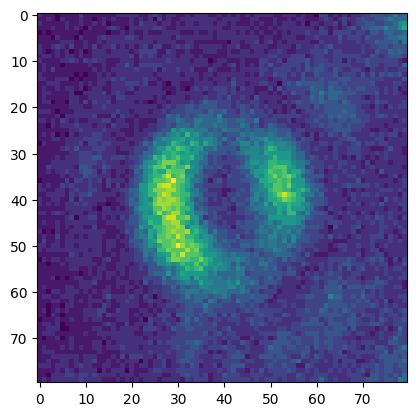

In [712]:
zernike_index = 6
expected_y = 330
expected_x = 980
crop_pixels = 40
refined_centre = pdf_bb[
    (pdf_bb['zernike_index'] == zernike_index) &
    (pdf_bb['expected_y'] == expected_y) &
    (pdf_bb['expected_x'] == expected_x) &
    (pdf_bb['w_index'] == 100)
][['refined_x','refined_y']].astype('int').values[0]
crop_details = (
    slice(refined_centre[1] - crop_pixels, refined_centre[1] + crop_pixels),
    slice(refined_centre[0] - crop_pixels, refined_centre[0] + crop_pixels)
)
plt.imshow(loaded[zernike_index]["images"][w][crop_details])

In [713]:
pdf_bb[
    (pdf_bb['zernike_index'] == zernike_index) &
    (pdf_bb['expected_y'] == expected_y) &
    (pdf_bb['expected_x'] == expected_x)
][['w_index','r_squared','rmse']]

,w_index,r_squared,rmse
1970,80,0.684073,0.126737
1986,81,0.685294,0.127032
2002,82,0.687263,0.125654
2018,83,0.689549,0.125185
2034,84,0.688059,0.124955
2050,85,0.692426,0.124424
2066,86,0.692266,0.114329
2082,87,0.687135,0.124540
2098,88,0.682530,0.125127
2114,89,0.688096,0.124828


In [ ]:
save_path = base_path / "data" / "zernike" / "raw" / "zernike_data_32_s_bb_100w_pdf_bb.csv"
pdf_bb.to_csv(save_path)